In [48]:
# Importing the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

In [49]:
# Installing openpyxl for reading Excel files
%pip install openpyxl
%pip install statsmodels
import statsmodels.formula.api as smf

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [50]:
# Loading/reading the Excel dataset
df = pd.read_excel("Monthly_traffic_data_1992-current.xlsx")

In [51]:
# Filtering the Excel dataset
df = pd.read_excel(
    "Monthly_traffic_data_1992-current.xlsx",
    header=[7, 8]
)

data = df[
    [
        ('Unnamed: 0_level_0', 'Year'),
        ('Unnamed: 1_level_0', 'Month'),
        ('Passengers', 'Total*')
    ]
].copy()

data.columns = ['Year', 'Month', 'Passengers']
data['Year'] = data['Year'].ffill()

months = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

data = data[data['Month'].isin(months)].copy()

data['Year'] = pd.to_numeric(data['Year'], errors='coerce')
data = data.dropna(subset=['Year'])
data['Year'] = data['Year'].astype(int)

data['Date'] = pd.to_datetime(
    data['Year'].astype(str) + ' ' + data['Month'],
    format='%Y %B'
)

# Calculate year-on-year percentage change
data = data.sort_values('Date').copy()

data['Year_on_year_change'] = (
    data['Passengers'].pct_change(periods=12) * 100
)

data.head(15)

,Year,Month,Passengers,Date,Year_on_year_change
0,1992,January,1149822.0,1992-01-01,NaN
1,1992,February,1086979.0,1992-02-01,NaN
2,1992,March,1276674.0,1992-03-01,NaN
3,1992,April,1522522.0,1992-04-01,NaN
4,1992,May,1742117.0,1992-05-01,NaN
5,1992,June,1737275.0,1992-06-01,NaN
6,1992,July,1979900.0,1992-07-01,NaN
7,1992,August,2061036.0,1992-08-01,NaN
8,1992,September,1867943.0,1992-09-01,NaN
9,1992,October,1707752.0,1992-10-01,NaN


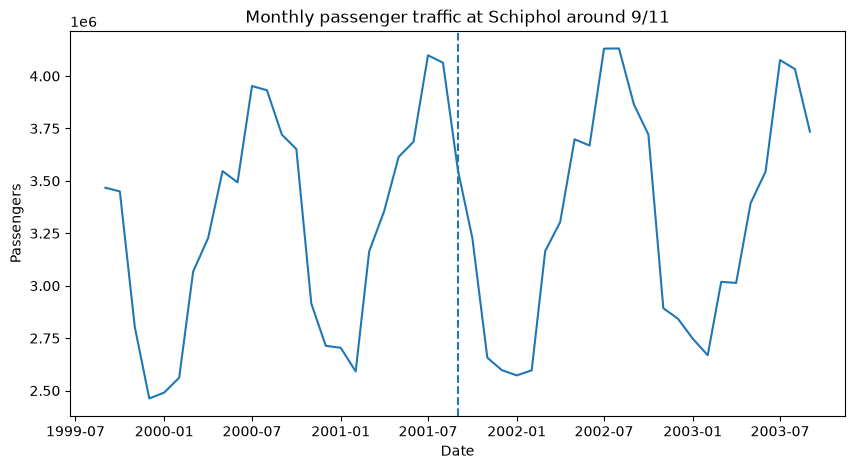

In [52]:
# Monthly passenger graph 9/11
event_911 = data[
    (data['Date'] >= '1999-09-01') &
    (data['Date'] <= '2003-09-01')
].copy()

plt.figure(figsize=(10, 5))

plt.plot(event_911['Date'], event_911['Passengers'])

plt.axvline(
    pd.Timestamp('2001-09-01'),
    linestyle='--'
)

plt.xlabel('Date')
plt.ylabel('Passengers')
plt.title('Monthly passenger traffic at Schiphol around 9/11')

plt.show()

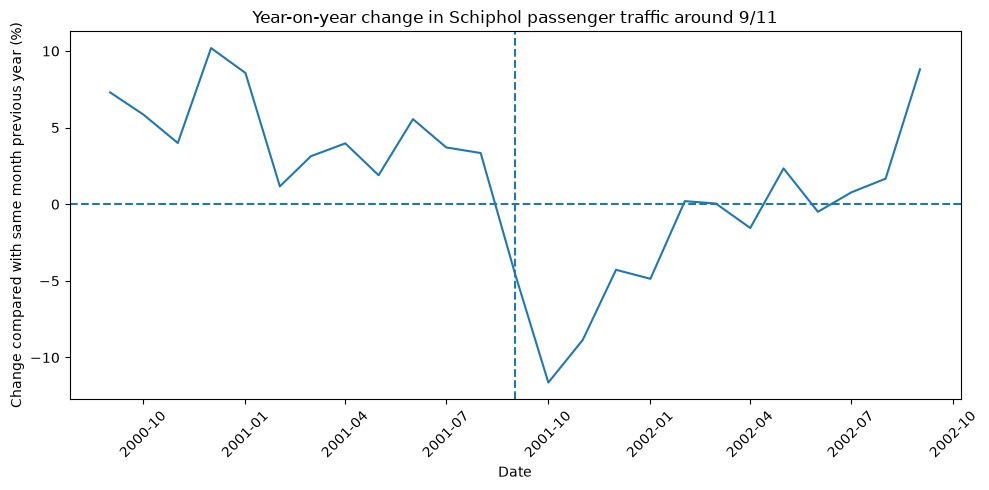

In [53]:
# Comparative graph for 9/11

# Select the comparison period
comparison_911 = event_911[
    (event_911['Date'] >= '2000-09-01') &
    (event_911['Date'] <= '2002-09-01')
].copy()

# Create the figure
plt.figure(figsize=(10, 5))

# Plot year-on-year percentage change
plt.plot(
    comparison_911['Date'],
    comparison_911['Year_on_year_change']
)

# Add a horizontal line at 0%
plt.axhline(0, linestyle='--')

# Mark the 9/11 event
plt.axvline(
    pd.Timestamp('2001-09-01'),
    linestyle='--'
)

# Labels and title
plt.xlabel('Date')
plt.ylabel('Change compared with same month previous year (%)')
plt.title('Year-on-year change in Schiphol passenger traffic around 9/11')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
# Calculate maximum impact of 9/11

# Select the period after 9/11
post_911 = comparison_911[
    comparison_911['Date'] >= '2001-09-01'
].copy()

# Find the month with the largest decline
max_impact_idx = post_911['Year_on_year_change'].idxmin()

max_impact_date = post_911.loc[max_impact_idx, 'Date']
max_impact_value = post_911.loc[max_impact_idx, 'Year_on_year_change']

event_date = pd.Timestamp('2001-09-01')

time_to_max_impact = (
    (max_impact_date.year - event_date.year) * 12
    + (max_impact_date.month - event_date.month)
)

# Display results
print("Month of maximum impact:", max_impact_date.strftime('%B %Y'))
print(f"Maximum impact: {max_impact_value:.2f}%")
print(f"Time to maximum impact: {time_to_max_impact} month(s)")

Month of maximum impact: October 2001
Maximum impact: -11.64%
Time to maximum impact: 1 month(s)


In [55]:
# Calculate duration of negative impact after 9/11

# Select months from September 2001 onwards
post_911 = comparison_911[
    comparison_911['Date'] >= '2001-09-01'
].sort_values('Date').copy()

# Count consecutive months with negative YoY change
duration = 0

for change in post_911['Year_on_year_change']:
    if change < 0:
        duration += 1
    else:
        break

print(f"Duration of negative impact: {duration} months")

Duration of negative impact: 5 months


In [56]:
# Calculate recovery time after 9/11

post_911 = event_911[
    event_911['Date'] >= '2001-09-01'
].sort_values('Date').copy()

# Find the first 3 consecutive months with non-negative YoY growth
recovery_date = None

for i in range(len(post_911) - 2):
    three_months = post_911['Year_on_year_change'].iloc[i:i+3]

    if (three_months >= 0).all():
        recovery_date = post_911['Date'].iloc[i]
        break

# Calculate recovery time in months
if recovery_date is not None:
    recovery_time = (
        (recovery_date.year - 2001) * 12
        + (recovery_date.month - 9)
    )

    print("Recovery month:", recovery_date.strftime('%B %Y'))
    print(f"Recovery time: {recovery_time} months")
else:
    print("No sustained recovery found within the selected period.")

Recovery month: July 2002
Recovery time: 10 months


In [57]:
# Select five years of historical data before 9/11

historical_911 = data[
    (data['Date'] >= '1996-09-01') &
    (data['Date'] < '2001-09-01')
].copy()

print("Start:", historical_911['Date'].min())
print("End:", historical_911['Date'].max())
print("Number of months:", len(historical_911))

Start: 1996-09-01 00:00:00
End: 2001-08-01 00:00:00
Number of months: 60


In [58]:
# Create prediction model based on 5 years of historical data

import statsmodels.formula.api as smf

# Prepare variables
historical_911 = historical_911.sort_values('Date').copy()

historical_911['Time'] = range(len(historical_911))
historical_911['Month_number'] = historical_911['Date'].dt.month

# Fit regression model
model_911 = smf.ols(
    'Passengers ~ Time + C(Month_number)',
    data=historical_911
).fit()

print("Prediction model created successfully!")

Prediction model created successfully!


In [59]:
# Predict passenger traffic after 9/11

# Select comparison period
prediction_911 = data[
    (data['Date'] >= '2001-09-01') &
    (data['Date'] <= '2003-09-01')
].sort_values('Date').copy()

# Prepare variables for prediction
prediction_911['Time'] = (
    (prediction_911['Date'].dt.year - 1996) * 12
    + (prediction_911['Date'].dt.month - 9)
)

prediction_911['Month_number'] = prediction_911['Date'].dt.month

# Calculate predicted passenger traffic
prediction_911['Predicted'] = model_911.predict(prediction_911)

# Display first results
print(prediction_911[['Date', 'Passengers', 'Predicted']].head())

          Date  Passengers   Predicted
125 2001-09-01   3551489.0  3851846.65
126 2001-10-01   3226663.0  3800309.65
127 2001-11-01   2656842.0  3197304.65
128 2001-12-01   2597484.0  3024645.85
130 2002-01-01   2572399.0  2996544.05


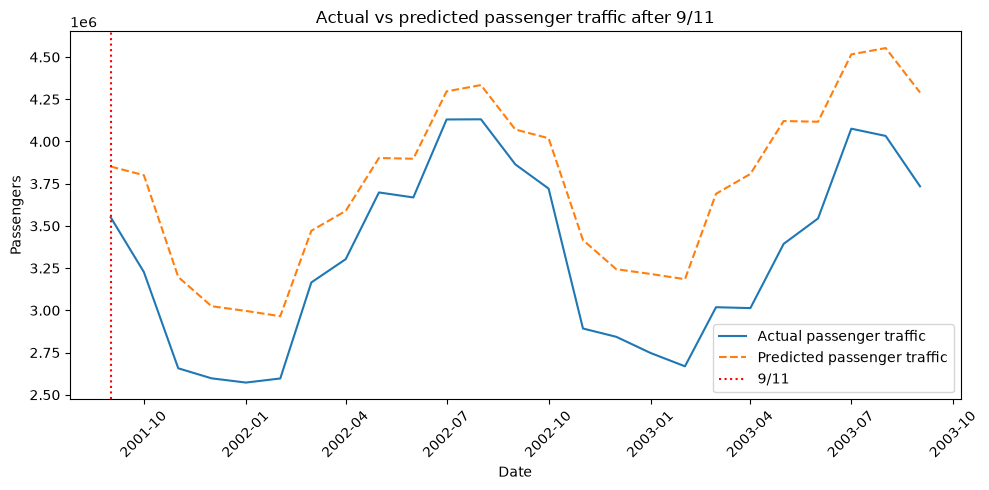

In [60]:
# Comparative graph: Actual vs predicted passenger traffic

plt.figure(figsize=(10, 5))

# Actual passenger traffic
plt.plot(
    prediction_911['Date'],
    prediction_911['Passengers'],
    label='Actual passenger traffic'
)

# Predicted passenger traffic
plt.plot(
    prediction_911['Date'],
    prediction_911['Predicted'],
    label='Predicted passenger traffic',
    linestyle='--'
)

# Mark 9/11
plt.axvline(
    pd.Timestamp('2001-09-01'),
    linestyle=':',
    color='red',
    label='9/11'
)

plt.xlabel('Date')
plt.ylabel('Passengers')
plt.title('Actual vs predicted passenger traffic after 9/11')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [61]:
# Calculate percentage deviation from predicted traffic

prediction_911['Deviation_pct'] = (
    (prediction_911['Passengers'] - prediction_911['Predicted'])
    / prediction_911['Predicted']
) * 100

print(
    prediction_911[
        ['Date', 'Deviation_pct']
    ].head(12)
)

          Date  Deviation_pct
125 2001-09-01      -7.797757
126 2001-10-01     -15.094734
127 2001-11-01     -16.903696
128 2001-12-01     -14.122706
130 2002-01-01     -14.154474
131 2002-02-01     -12.436571
132 2002-03-01      -8.817650
133 2002-04-01      -7.959672
134 2002-05-01      -5.225655
135 2002-06-01      -5.880296
136 2002-07-01      -3.868486
137 2002-08-01      -4.679237


In [62]:
# Results table for 9/11

# Calculate deviation from predicted passenger traffic
prediction_911['Deviation_pct'] = (
    (prediction_911['Passengers'] - prediction_911['Predicted'])
    / prediction_911['Predicted']
) * 100

# Find maximum negative deviation
max_deviation_idx = prediction_911['Deviation_pct'].idxmin()

# Create results table
results_911 = pd.DataFrame({
    'Indicator': [
        'Maximum YoY decline',
        'Month of maximum YoY decline',
        'Time to maximum decline',
        'Duration of negative YoY growth',
        'Recovery month',
        'Recovery time',
        'Maximum deviation from prediction',
        'Month of maximum deviation'
    ],
    'Result': [
        f'{max_impact_value:.2f}%',
        max_impact_date.strftime('%B %Y'),
        f'{time_to_max_impact} month(s)',
        f'{duration} months',
        recovery_date.strftime('%B %Y'),
        f'{recovery_time} months',
        f"{prediction_911.loc[max_deviation_idx, 'Deviation_pct']:.2f}%",
        prediction_911.loc[max_deviation_idx, 'Date'].strftime('%B %Y')
    ]
})

display(results_911)

,Indicator,Result
0,Maximum YoY decline,-11.64%
1,Month of maximum YoY decline,October 2001
2,Time to maximum decline,1 month(s)
3,Duration of negative YoY growth,5 months
4,Recovery month,July 2002
5,Recovery time,10 months
6,Maximum deviation from prediction,-20.86%
7,Month of maximum deviation,April 2003
